Lithium Carbonate Price Forecasting — Part 1: Data Import & Exploratory Analysis
Goal: understand and validate the consolidated monthly dataset before building forecasting models.

First we inspect the target price, coverage, missing data, and relationships among candidate predictors.

Important: the consolidated workbook contains a selected price series that changes source over time. The workbook's Selected target source column identifies the source used each month. Keep this source transition in mind when interpreting the long historical trend and when later evaluating models.

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


df = pd.read_csv("lithium_data_consolidated.csv")

# Parse dates and sort chronologically
df["Month"] = pd.to_datetime(df["Month"], errors="coerce")
df = df.dropna(subset=["Month"]).sort_values("Month").reset_index(drop=True)

print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Date range:", df["Month"].min().date(), "to", df["Month"].max().date())

display(df.head())


Rows: 209
Columns: 36
Date range: 2009-06-01 to 2026-10-01


,Month,Selected lithium carbonate price (CNY/t),Selected target source,Lithium carbonate price (CNY/metric tonne),China spot lithium carbonate price (CNY/t) - CSV,Albemarle share price (USD/share),SQM share price (USD/ADR),Tesla share price (USD/share),LME nickel price (USD/metric tonne),LME copper price (USD/metric tonne),...,China spot price volume (CSV),China spot price change (%) - CSV,"Japan, Inventory - Lithium Batteries","China, Lithium Iron Phosphate Power Battery Sales","Japan, Shipments - Lithium Batteries","Japan, Production - Lithium Batteries","Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100","China, Pure Electric Vehicle Sales","China, Lithium Ion Battery Production",LME cobalt cash price (USD/metric tonne) - updated Datastream
0,2009-06-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,-5.26,35840.0,NaN,37551.0,86577.0,NaN,NaN,1.611004e+08,NaN
1,2009-07-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,0.00,30170.0,NaN,31598.0,89541.0,NaN,NaN,1.815160e+08,NaN
2,2009-08-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,0.00,31600.0,NaN,28765.0,82362.0,NaN,NaN,1.708017e+08,NaN
3,2009-09-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,0.00,31678.0,NaN,35090.0,88140.0,NaN,NaN,1.908061e+08,NaN
4,2009-10-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,0.00,26179.0,NaN,35422.0,89872.0,NaN,NaN,1.837243e+08,NaN


In [29]:
df.info()

display(pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(1)
}).sort_values("missing_percent"))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 36 columns):
 #   Column                                                                  Non-Null Count  Dtype         
---  ------                                                                  --------------  -----         
 0   Month                                                                   209 non-null    datetime64[ns]
 1   Selected lithium carbonate price (CNY/t)                                209 non-null    float64       
 2   Selected target source                                                  209 non-null    object        
 3   Lithium carbonate price (CNY/metric tonne)                              90 non-null     float64       
 4   China spot lithium carbonate price (CNY/t) - CSV                        186 non-null    float64       
 5   Albemarle share price (USD/share)                                       90 non-null     float64       
 6   SQM share price (USD/ADR) 

,data_type,non_missing,missing,missing_percent
Month,datetime64[ns],209,0,0.0
Selected lithium carbonate price (CNY/t),float64,209,0,0.0
Selected target source,object,209,0,0.0
"Japan, Production - Lithium Batteries",float64,207,2,1.0
"Japan, Shipments - Lithium Batteries",float64,207,2,1.0
"Japan, Inventory - Lithium Batteries",float64,207,2,1.0
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",float64,201,8,3.8
LME cobalt cash price (USD/metric tonne) - updated Datastream,float64,197,12,5.7
China spot lithium carbonate price (CNY/t) - CSV,float64,186,23,11.0
China spot price change (%) - CSV,float64,186,23,11.0


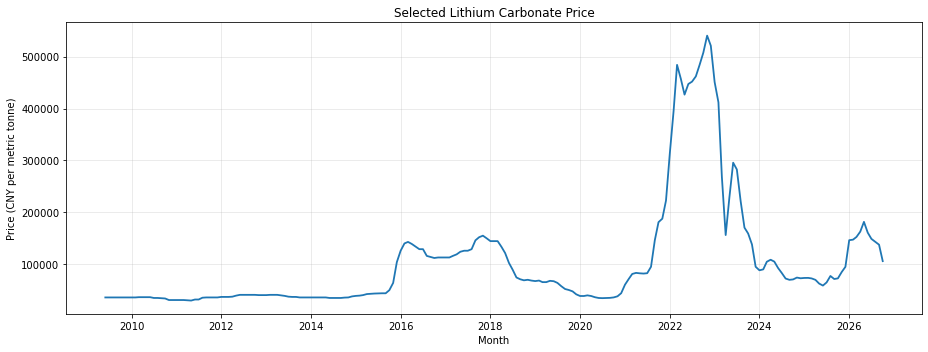

,observations,first_month,last_month,average_price
Selected target source,,,,
China spot CSV,119,2009-06-01,2019-04-01,63936.97
"Refinitiv weekly observations, monthly average",90,2019-05-01,2026-10-01,156035.12


In [30]:
TARGET = "Selected lithium carbonate price (CNY/t)"
SOURCE = "Selected target source"

if TARGET not in df.columns:
    raise KeyError(f"Target column not found: {TARGET}")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df["Month"], df[TARGET], linewidth=1.8)
ax.set_title("Selected Lithium Carbonate Price")
ax.set_xlabel("Month")
ax.set_ylabel("Price (CNY per metric tonne)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

if SOURCE in df.columns:
    display(df.groupby(SOURCE, dropna=False).agg(
        observations=(TARGET, "count"),
        first_month=("Month", "min"),
        last_month=("Month", "max"),
        average_price=(TARGET, "mean")
    ).round(2))


In [31]:
duplicate_pairs = []
cols = list(df.columns)

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        a, b = cols[i], cols[j]
        if df[a].equals(df[b]):
            duplicate_pairs.append((a, b))

print("Exact duplicate column pairs:")
for pair in duplicate_pairs:
    print(" -", pair)
if not duplicate_pairs:
    print("No exact duplicate columns detected.")


Exact duplicate column pairs:
No exact duplicate columns detected.


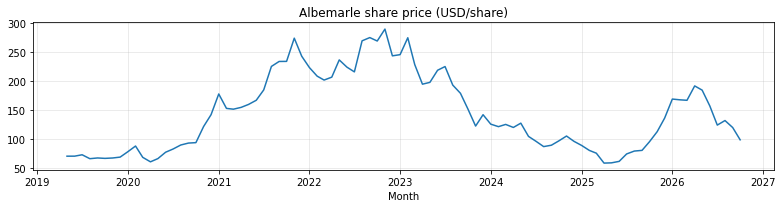

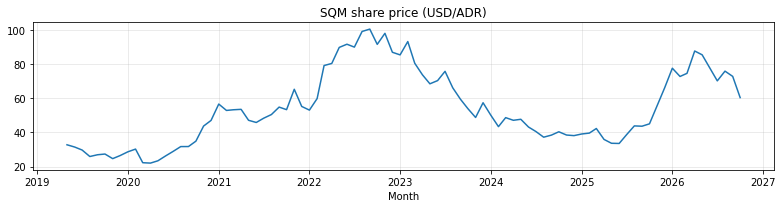

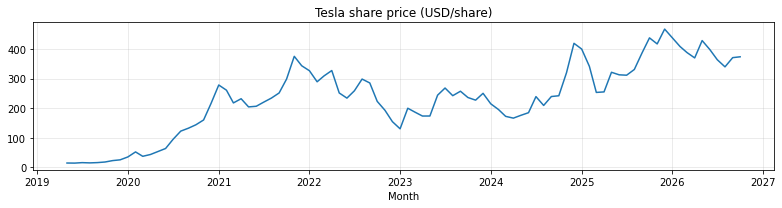

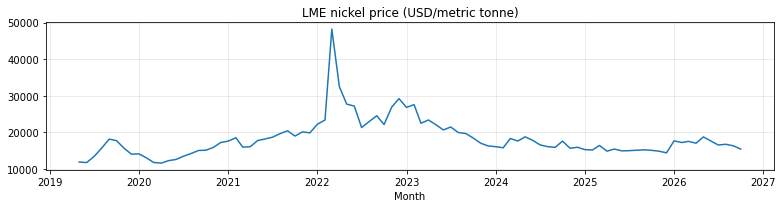

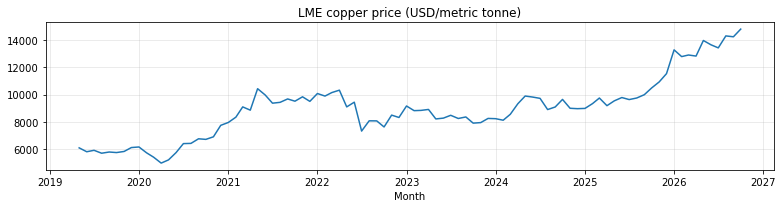

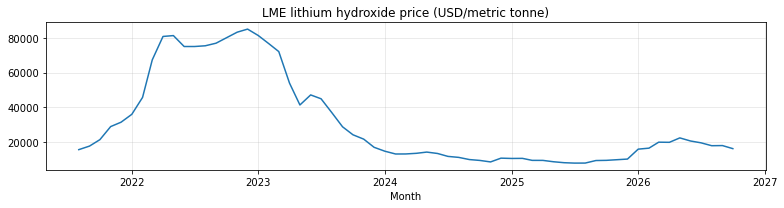

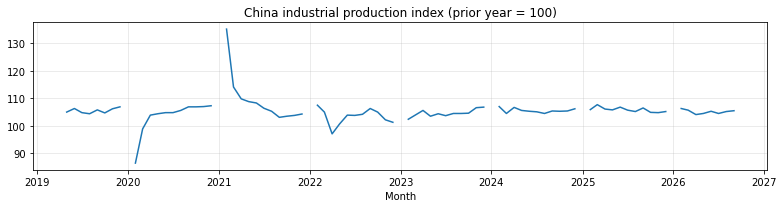

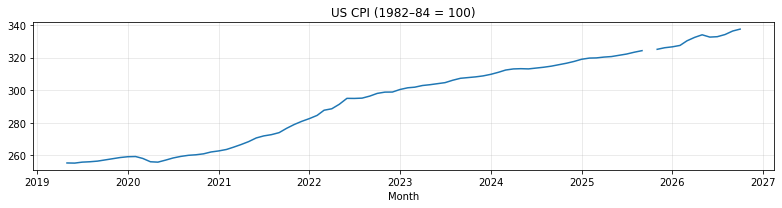

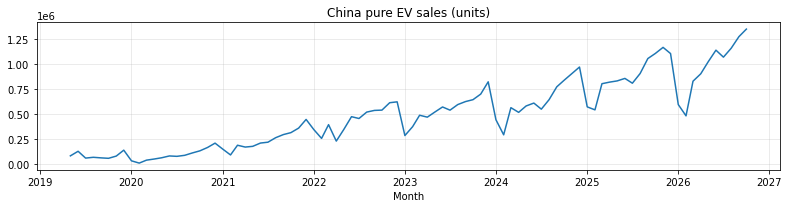

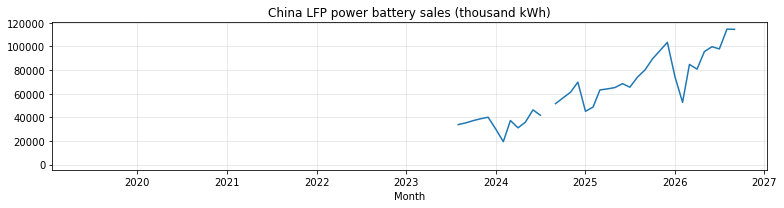

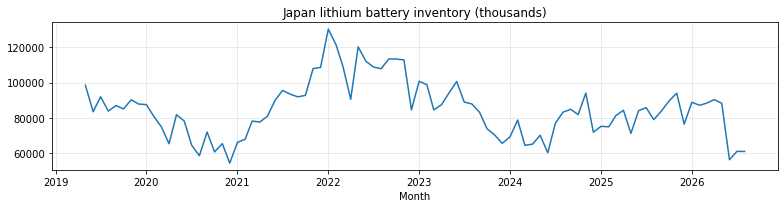

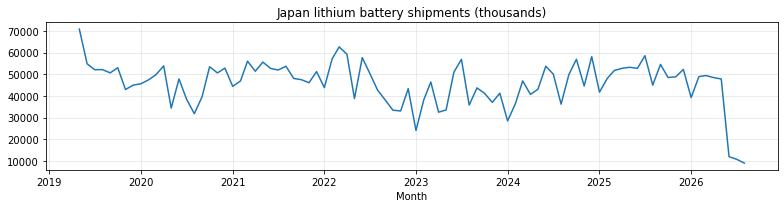

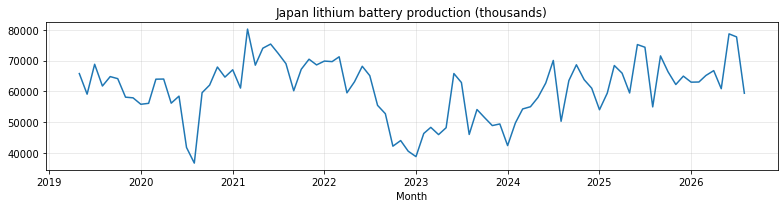

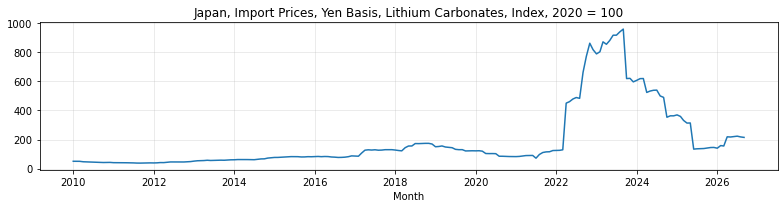

In [32]:
candidate_columns = [
    "Albemarle share price (USD/share)",
    "SQM share price (USD/ADR)",
    "Tesla share price (USD/share)",
    "LME nickel price (USD/metric tonne)",
    "LME copper price (USD/metric tonne)",
    "LME cobalt settlement price (USD/metric tonne)",
    "LME lithium hydroxide price (USD/metric tonne)",
    "China industrial production index (prior year = 100)",
    "US CPI (1982–84 = 100)",
    "China pure EV sales (units)",
    "China LFP power battery sales (thousand kWh)",
    "Japan lithium battery inventory (thousands)",
    "Japan lithium battery shipments (thousands)",
    "Japan lithium battery production (thousands)",
    "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
]

candidate_columns = [c for c in candidate_columns if c in df.columns]

for col in candidate_columns:
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(df["Month"], df[col])
    ax.set_title(col)
    ax.set_xlabel("Month")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


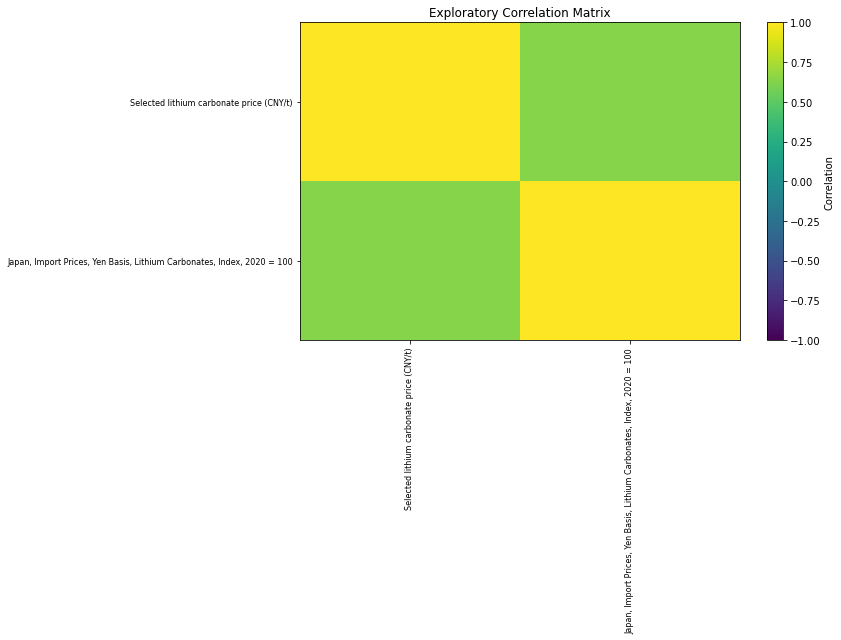

,correlation_with_target
Selected lithium carbonate price (CNY/t),1.000000
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",0.634798


In [33]:
# Use the selected target and candidate variables only for this first correlation view.
corr_columns = [TARGET] + candidate_columns
corr_data = df[corr_columns].copy()

# Keep variables with at least 70% coverage in the full monthly panel.
coverage = corr_data.notna().mean()
corr_columns_kept = coverage[coverage >= 0.70].index.tolist()
corr_data = corr_data[corr_columns_kept]

corr = corr_data.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.index)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticklabels(corr.index, fontsize=8)
ax.set_title("Exploratory Correlation Matrix")
fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

display(corr[TARGET].sort_values(ascending=False).to_frame("correlation_with_target"))


In [34]:
coverage_table = pd.DataFrame({
    "first_available_month": df[candidate_columns].apply(lambda s: df.loc[s.first_valid_index(), "Month"] if s.first_valid_index() is not None else pd.NaT),
    "last_available_month": df[candidate_columns].apply(lambda s: df.loc[s.last_valid_index(), "Month"] if s.last_valid_index() is not None else pd.NaT),
    "observations": df[candidate_columns].notna().sum(),
    "coverage_percent": (df[candidate_columns].notna().mean() * 100).round(1)
}).sort_values("coverage_percent", ascending=False)

display(coverage_table)


,first_available_month,last_available_month,observations,coverage_percent
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",2010-01-01,2026-09-01,201,96.2
Albemarle share price (USD/share),2019-05-01,2026-10-01,90,43.1
SQM share price (USD/ADR),2019-05-01,2026-10-01,90,43.1
Tesla share price (USD/share),2019-05-01,2026-10-01,90,43.1
LME nickel price (USD/metric tonne),2019-05-01,2026-10-01,90,43.1
LME copper price (USD/metric tonne),2019-05-01,2026-10-01,90,43.1
China pure EV sales (units),2019-05-01,2026-10-01,90,43.1
US CPI (1982–84 = 100),2019-05-01,2026-10-01,89,42.6
Japan lithium battery inventory (thousands),2019-05-01,2026-08-01,88,42.1
Japan lithium battery shipments (thousands),2019-05-01,2026-08-01,88,42.1


In [35]:
# Current lithium price can be used to forecast the following month.
PRICE_LAGS = [0, 1, 2, 3, 5, 10]

# Other market variables are lagged at least one month to reduce
# the risk of using data that was not yet published at the forecast date.
OTHER_LAGS = [1]

TEST_SIZE = 0.20
RANDOM_STATE = 42

In [36]:
candidate_variables = [
    "LME nickel price (USD/metric tonne)",
    "LME copper price (USD/metric tonne)",
    "LME cobalt cash price (USD/metric tonne) - updated Datastream",
    "Albemarle share price (USD/share)",
    "SQM share price (USD/ADR)",
    "China pure EV sales (units)",
    "CNY/USD exchange-rate series (source quote)"
]

variables = [col for col in candidate_variables if col in df.columns]
missing_variables = [col for col in candidate_variables if col not in df.columns]

print("Included predictors:")
for col in variables:
    print(" -", col)

if missing_variables:
    print("\nNot found in workbook (skipped):")
    for col in missing_variables:
        print(" -", col)

if not variables:
    raise ValueError("None of the candidate predictor columns were found.")

Included predictors:
 - LME nickel price (USD/metric tonne)
 - LME copper price (USD/metric tonne)
 - LME cobalt cash price (USD/metric tonne) - updated Datastream
 - Albemarle share price (USD/share)
 - SQM share price (USD/ADR)
 - China pure EV sales (units)
 - CNY/USD exchange-rate series (source quote)


In [37]:
coverage = pd.DataFrame({
    "Non-missing": df[variables].notna().sum(),
    "Missing": df[variables].isna().sum(),
    "Coverage (%)": (df[variables].notna().mean() * 100).round(1),
    "First month": [df[col].first_valid_index() for col in variables],
    "Last month": [df[col].last_valid_index() for col in variables]
})
display(coverage)

,Non-missing,Missing,Coverage (%),First month,Last month
LME nickel price (USD/metric tonne),90,119,43.1,119,208
LME copper price (USD/metric tonne),90,119,43.1,119,208
LME cobalt cash price (USD/metric tonne) - updated Datastream,197,12,94.3,12,208
Albemarle share price (USD/share),90,119,43.1,119,208
SQM share price (USD/ADR),90,119,43.1,119,208
China pure EV sales (units),90,119,43.1,119,208
CNY/USD exchange-rate series (source quote),90,119,43.1,119,208


In [39]:
model_data = pd.DataFrame(index=df.index)
features = []

# Lagged lithium carbonate prices
for lag in PRICE_LAGS:
    name = f"LithiumPrice_lag{lag}"
    model_data[name] = df[TARGET].shift(lag)
    features.append(name)

# Lagged explanatory variables
for variable in variables:
    safe_name = (variable.replace(" ", "_")
                        .replace("/", "_")
                        .replace("(", "")
                        .replace(")", "")
                        .replace(",", ""))

    for lag in OTHER_LAGS:
        name = f"{safe_name}_lag{lag}"
        model_data[name] = pd.to_numeric(
            df[variable], errors="coerce"
        ).shift(lag)
        features.append(name)

# Predict next month's lithium carbonate price
model_data["LithiumPrice_next_month"] = df[TARGET].shift(-1)
model_data["TargetDate"] = df["Month"].shift(-1)

# Ensure dates are datetime
model_data["TargetDate"] = pd.to_datetime(
    model_data["TargetDate"], errors="coerce"
)

# Remove incomplete observations
model_data = (model_data
              .dropna(subset=features + [
                  "LithiumPrice_next_month", "TargetDate"
              ])
              .sort_values("TargetDate")
              .reset_index(drop=True))

print("Modeling observations:", len(model_data))
print("Number of predictors:", len(features))
print("Forecast target period:",
      model_data["TargetDate"].min().strftime("%Y-%m-%d"),
      "to",
      model_data["TargetDate"].max().strftime("%Y-%m-%d"))

display(model_data.head())

Modeling observations: 88
Number of predictors: 13
Forecast target period: 2019-07-01 to 2026-10-01


,LithiumPrice_lag0,LithiumPrice_lag1,LithiumPrice_lag2,LithiumPrice_lag3,LithiumPrice_lag5,LithiumPrice_lag10,LME_nickel_price_USD_metric_tonne_lag1,LME_copper_price_USD_metric_tonne_lag1,LME_cobalt_cash_price_USD_metric_tonne_-_updated_Datastream_lag1,Albemarle_share_price_USD_share_lag1,SQM_share_price_USD_ADR_lag1,China_pure_EV_sales_units_lag1,CNY_USD_exchange-rate_series_source_quote_lag1,LithiumPrice_next_month,TargetDate
0,67250.0,68000.0,65500.0,65500.0,67500.0,74500.0,11885.0,6108.00,34500.0,70.0040,32.731000,83232.0,6.851640,64000.0,2019-07-01
1,64000.0,67250.0,68000.0,65500.0,68500.0,71000.0,11757.0,5823.00,28000.0,70.0575,31.409325,129111.0,6.890075,57700.0,2019-08-01
2,57700.0,64000.0,67250.0,68000.0,65500.0,69000.0,13409.5,5928.75,26650.0,72.4325,29.644900,60868.0,6.873600,52250.0,2019-09-01
3,52250.0,57700.0,64000.0,67250.0,65500.0,70000.0,15680.0,5715.75,31008.0,65.6900,25.856060,68799.0,7.041180,50400.0,2019-10-01
4,50400.0,52250.0,57700.0,64000.0,68000.0,68500.0,18153.0,5803.25,35975.5,66.9325,26.887875,63019.0,7.114250,47750.0,2019-11-01


In [40]:
split = int(len(model_data) * (1 - TEST_SIZE))

train_data = model_data.iloc[:split].copy()
test_data = model_data.iloc[split:].copy()

X_train = train_data[features]
y_train = train_data["LithiumPrice_next_month"]

X_test = test_data[features]
y_test = test_data["LithiumPrice_next_month"]

test_dates = test_data["TargetDate"]

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))
print("Training target dates:",
      train_data["TargetDate"].min().date(), "to",
      train_data["TargetDate"].max().date())
print("Testing target dates:",
      test_dates.min().date(), "to", test_dates.max().date())

Training observations: 70
Testing observations: 18
Training target dates: 2019-07-01 to 2025-04-01
Testing target dates: 2025-05-01 to 2026-10-01


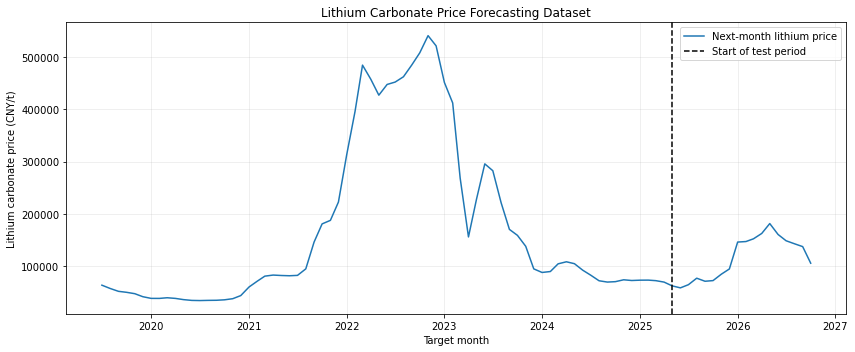

In [21]:
plt.figure(figsize=(12, 5))
plt.plot(model_data["TargetDate"], model_data["LithiumPrice_next_month"],
         label="Next-month lithium price", linewidth=1.5)
plt.axvline(test_dates.min(), color="black", linestyle="--",
            label="Start of test period")
plt.title("Lithium Carbonate Price Forecasting Dataset")
plt.xlabel("Target month")
plt.ylabel("Lithium carbonate price (CNY/t)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [41]:
model_data.to_csv("lithium_model_data.csv", index=False)
train_data.to_csv("lithium_train_data.csv", index=False)
test_data.to_csv("lithium_test_data.csv", index=False)

print("Saved:")
print(" - lithium_model_data.csv")
print(" - lithium_train_data.csv")
print(" - lithium_test_data.csv")

Saved:
 - lithium_model_data.csv
 - lithium_train_data.csv
 - lithium_test_data.csv


In [42]:
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 3

TARGET_COL = "LithiumPrice_next_month"
DATE_COL = "TargetDate"

In [43]:
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

models = {
    "Regression Tree": (
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {
            "max_depth": [2, 3, 5],
            "min_samples_leaf": [2, 4, 6]
        }
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        {
            "n_estimators": [100, 300],
            "max_depth": [2, 4, None],
            "min_samples_leaf": [2, 4]
        }
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {
            "n_estimators": [50, 100],
            "learning_rate": [0.03, 0.05, 0.1],
            "max_depth": [1, 2],
            "min_samples_leaf": [2, 4]
        }
    )
}

print("Models ready:", list(models.keys()))

Models ready: ['Regression Tree', 'Random Forest', 'Gradient Boosting']


In [44]:
searches = {}
best_models = {}
cv_rows = []

for name, (estimator, param_grid) in models.items():
    print(f"Fitting {name}...")

    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring="neg_mean_absolute_error",
        cv=tscv,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    searches[name] = search
    best_models[name] = search.best_estimator_

    cv_rows.append({
        "Model": name,
        "Best CV MAE": -search.best_score_,
        "Best parameters": search.best_params_
    })

cv_results = pd.DataFrame(cv_rows).sort_values("Best CV MAE")
display(cv_results)

Fitting Regression Tree...
Fitting Random Forest...
Fitting Gradient Boosting...


,Model,Best CV MAE,Best parameters
2,Gradient Boosting,97920.804648,"{'learning_rate': 0.1, 'max_depth': 2, 'min_sa..."
0,Regression Tree,99182.822524,"{'max_depth': 2, 'min_samples_leaf': 2}"
1,Random Forest,100329.468387,"{'max_depth': 2, 'min_samples_leaf': 2, 'n_est..."


In [45]:
predictions = {}

for name, model in best_models.items():
    predictions[name] = model.predict(X_test)

# Random Walk: next month's price = current month's price
if "LithiumPrice_lag0" not in X_test.columns:
    raise KeyError("LithiumPrice_lag0 is missing. Check the lagged price features from Part 2.")

predictions["Random Walk"] = X_test["LithiumPrice_lag0"].to_numpy()

# Actual-versus-predicted table
prediction_data = pd.DataFrame({
    "TargetDate": test_dates.to_numpy(),
    "Actual": y_test.to_numpy()
})

for name, values in predictions.items():
    prediction_data[name] = values

display(prediction_data.head())

,TargetDate,Actual,Regression Tree,Random Forest,Gradient Boosting,Random Walk
0,2025-05-01,62740.0,65623.104651,66618.936505,71318.980475,69887.5
1,2025-06-01,58875.0,65623.104651,66618.936505,68320.204275,62740.0
2,2025-07-01,64940.0,65623.104651,66618.936505,63513.109352,58875.0
3,2025-08-01,77337.5,65623.104651,66618.936505,69054.320438,64940.0
4,2025-09-01,71500.0,65623.104651,66618.936505,71906.839556,77337.5


In [46]:
metric_rows = []

for name, y_pred in predictions.items():
    metric_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results = (pd.DataFrame(metric_rows)
           .sort_values("MAE")
           .reset_index(drop=True))

display(results.round(3))

,Model,MAE,MSE,RMSE,R2
0,Random Walk,12283.472,2.950602e+08,17177.315,0.820
1,Gradient Boosting,23097.241,1.012827e+09,31824.936,0.383
2,Random Forest,35128.161,2.205342e+09,46961.071,-0.343
3,Regression Tree,46091.516,3.467424e+09,58884.837,-1.111


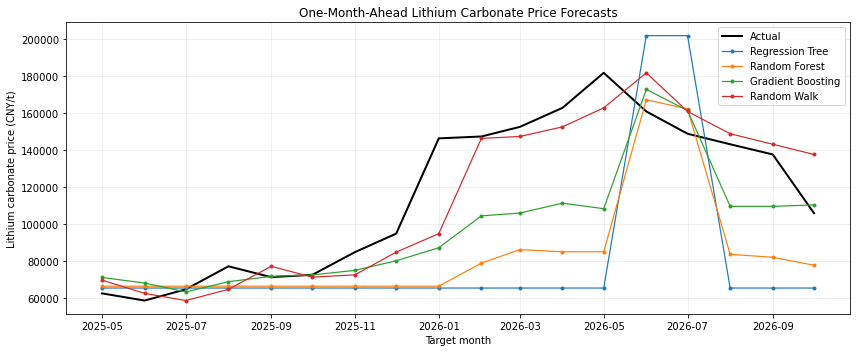

In [47]:
plt.figure(figsize=(12, 5))
plt.plot(test_dates, y_test.to_numpy(), color="black",
         linewidth=2, label="Actual")

for name, y_pred in predictions.items():
    plt.plot(test_dates, y_pred, marker="o", markersize=3,
             linewidth=1.2, label=name)

plt.title("One-Month-Ahead Lithium Carbonate Price Forecasts")
plt.xlabel("Target month")
plt.ylabel("Lithium carbonate price (CNY/t)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

,Importance
LithiumPrice_lag0,0.816652
Albemarle_share_price_USD_share_lag1,0.072692
LME_nickel_price_USD_metric_tonne_lag1,0.055065
LME_cobalt_cash_price_USD_metric_tonne_-_updated_Datastream_lag1,0.014801
LithiumPrice_lag10,0.013711
LithiumPrice_lag1,0.011826
LithiumPrice_lag2,0.010230
SQM_share_price_USD_ADR_lag1,0.001654
LME_copper_price_USD_metric_tonne_lag1,0.001519
LithiumPrice_lag3,0.001052


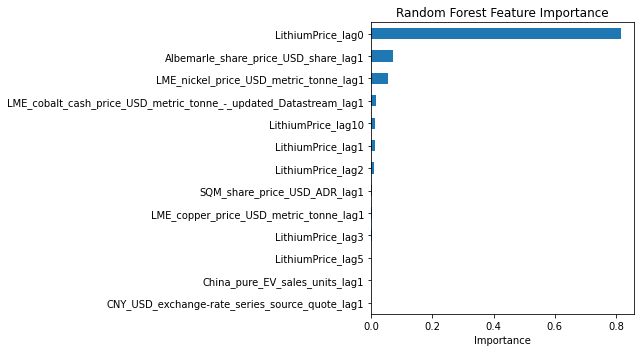

In [48]:
if "Random Forest" in best_models:
    importance = pd.Series(
        best_models["Random Forest"].feature_importances_,
        index=features
    ).sort_values(ascending=False)

    display(importance.to_frame("Importance"))

    plt.figure(figsize=(9, 5))
    importance.sort_values().plot(kind="barh")
    plt.title("Random Forest Feature Importance")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

In [49]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel

In [50]:
# Scale predictors using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Gaussian Process kernel
kernel = (
    ConstantKernel(1.0, (1e-2, 1e2))
    * RBF(length_scale=1.0, length_scale_bounds=(1e-2, 1e2))
    + WhiteKernel(noise_level=1.0, noise_level_bounds=(1e-5, 1e2))
)

gpr = GaussianProcessRegressor(
    kernel=kernel,
    normalize_y=True,
    n_restarts_optimizer=2,
    random_state=RANDOM_STATE
)

gpr.fit(X_train_scaled, y_train)

# Predictive mean and standard deviation
gpr_mean, gpr_std = gpr.predict(X_test_scaled, return_std=True)

# Approximate 95% predictive intervals
gpr_lower = gpr_mean - 1.96 * gpr_std
gpr_upper = gpr_mean + 1.96 * gpr_std

predictions["Gaussian Process"] = gpr_mean

print("Optimized kernel:")
print(gpr.kernel_)

gpr_intervals = pd.DataFrame({
    "TargetDate": test_dates.to_numpy(),
    "Actual": y_test.to_numpy(),
    "GPR forecast": gpr_mean,
    "Predictive std": gpr_std,
    "95% lower": gpr_lower,
    "95% upper": gpr_upper
})

display(gpr_intervals.head())

Optimized kernel:
0.829**2 * RBF(length_scale=2.73) + WhiteKernel(noise_level=2.96e-05)


,TargetDate,Actual,GPR forecast,Predictive std,95% lower,95% upper
0,2025-05-01,62740.0,61726.724226,23545.914618,15576.731575,107876.716876
1,2025-06-01,58875.0,61832.677270,25310.343892,12224.403242,111440.951299
2,2025-07-01,64940.0,59945.612215,26574.685758,7859.228130,112031.996300
3,2025-08-01,77337.5,60897.029036,29011.509618,4034.470184,117759.587887
4,2025-09-01,71500.0,61520.362887,25690.317382,11167.340818,111873.384956


95% interval test coverage: 100.0%
Mean 95% interval width: 265,401.17 CNY/t


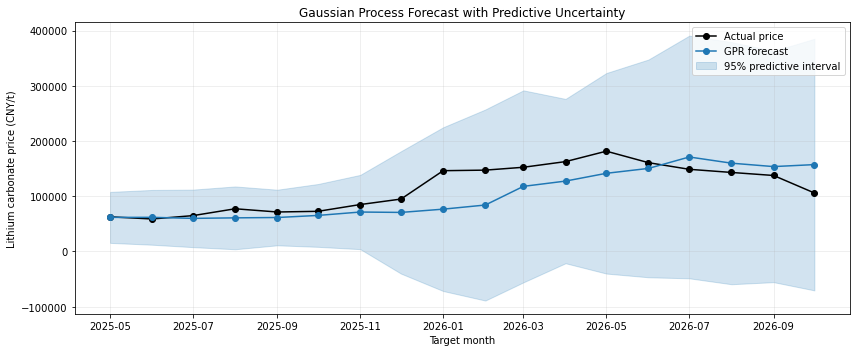

In [51]:
coverage_95 = np.mean(
    (y_test.to_numpy() >= gpr_lower) &
    (y_test.to_numpy() <= gpr_upper)
)

mean_interval_width = np.mean(gpr_upper - gpr_lower)

print(f"95% interval test coverage: {coverage_95:.1%}")
print(f"Mean 95% interval width: {mean_interval_width:,.2f} CNY/t")

plt.figure(figsize=(12, 5))
plt.plot(test_dates, y_test.to_numpy(), color="black",
         marker="o", label="Actual price")
plt.plot(test_dates, gpr_mean, color="tab:blue",
         marker="o", label="GPR forecast")
plt.fill_between(test_dates, gpr_lower, gpr_upper,
                 color="tab:blue", alpha=0.2, label="95% predictive interval")
plt.title("Gaussian Process Forecast with Predictive Uncertainty")
plt.xlabel("Target month")
plt.ylabel("Lithium carbonate price (CNY/t)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

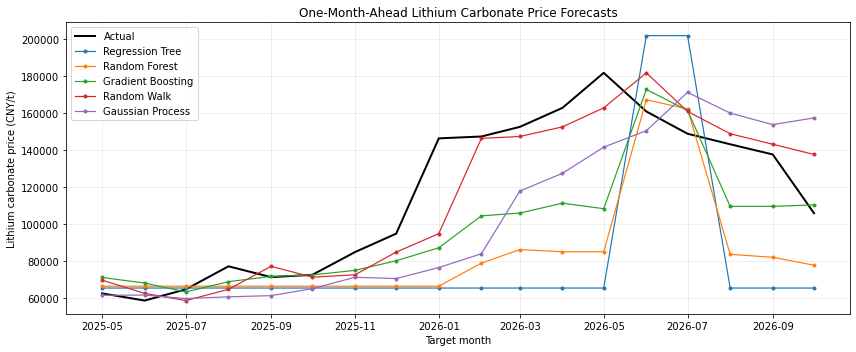

In [52]:
plt.figure(figsize=(12, 5))
plt.plot(test_dates, y_test.to_numpy(), color="black",
         linewidth=2, label="Actual")

for name, y_pred in predictions.items():
    plt.plot(test_dates, y_pred, marker="o", markersize=3,
             linewidth=1.2, label=name)

plt.title("One-Month-Ahead Lithium Carbonate Price Forecasts")
plt.xlabel("Target month")
plt.ylabel("Lithium carbonate price (CNY/t)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()